In [1]:
# -----------------------------------------------------------------------
# Libraries and Reproducibility setup
# -----------------------------------------------------------------------

import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
from scipy import stats
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (Matern, ConstantKernel, WhiteKernel)
from scipy.stats import norm, shapiro, qmc, skew, pearsonr, spearmanr
from scipy.optimize import minimize
from sklearn.model_selection import LeaveOneOut
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
rng = np.random.default_rng(SEED)

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

# ---------------------------------------------------------------- 
# Figures settings
# ---------------------------------------------------------------- 
SURFACE, INK, INK2, MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
BLUE, ORANGE, AQUA, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#e87ba4"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [2]:
# -----------------------------------------------------------------------
# DATA
# -----------------------------------------------------------------------
X = np.load('..\Function_7_Data\Week_11_Data/F7_Week_11_inputs.npy')
y = np.load('..\Function_7_Data\Week_11_Data/F7_Week_11_outputs.npy')
n, d = X.shape
N_INITIAL = 30
best = int(np.argmax(y))
xb = X[best]
print(f"n = {n} ({N_INITIAL} initial + {n - N_INITIAL} queried); newest x = {np.round(X[-1], 6)}, y = {y[-1]:.6f}")
print(f"best observed: row {best}, x = {np.round(xb, 6)}, y = {y[best]:.6f}")

n = 40 (30 initial + 10 queried); newest x = [0.       0.208883 0.399928 0.312161 0.326241 0.644055], y = 2.714393
best observed: row 39, x = [0.       0.208883 0.399928 0.312161 0.326241 0.644055], y = 2.714393


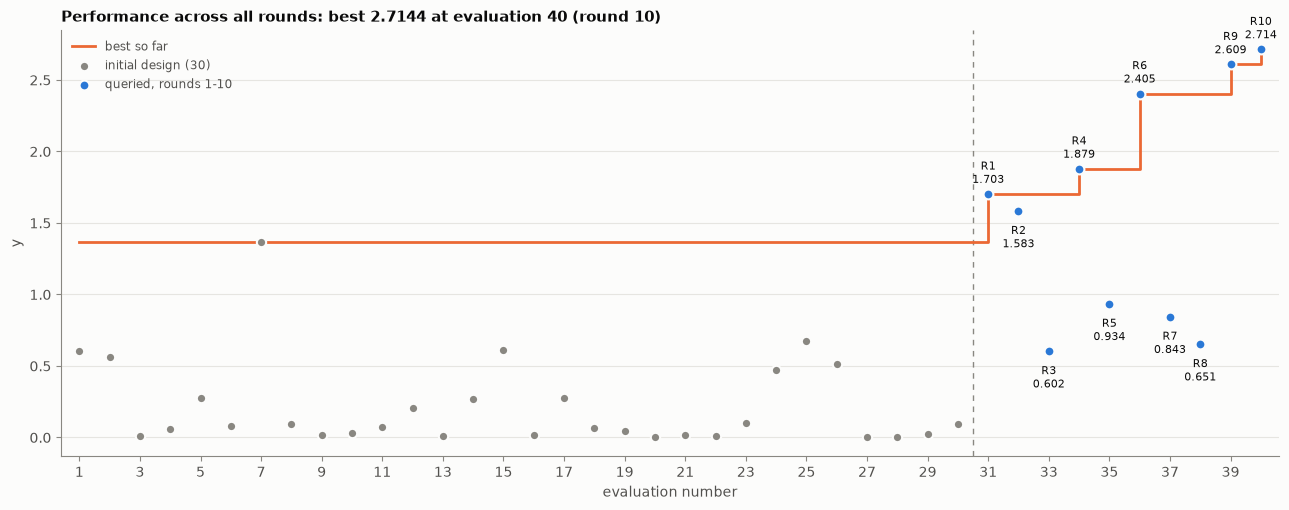

In [3]:
# Performance across all rounds
idx = np.arange(1, n + 1)
bsf = np.maximum.accumulate(np.r_[np.full(N_INITIAL, y[:N_INITIAL].max()), y[N_INITIAL:]])
fig, ax = plt.subplots(figsize=(13, 5.2))
ax.axvline(N_INITIAL + 0.5, color=MUTED, lw=1, ls=(0, (4, 4)))
ax.step(idx, bsf, where="post", color=PAL[1], lw=2, label="best so far", zorder=2)
ax.scatter(idx[:N_INITIAL], y[:N_INITIAL], s=45, color=MUTED, edgecolor=SURFACE, linewidth=1.5, label=f"initial design ({N_INITIAL})", zorder=3)
ax.scatter(idx[N_INITIAL:], y[N_INITIAL:], s=50, color=PAL[0], edgecolor=SURFACE, linewidth=1.5, label=f"queried, rounds 1-{n - N_INITIAL}", zorder=3)
for i in range(N_INITIAL, n):
    ax.annotate(f"R{i - N_INITIAL + 1}\n{y[i]:.3f}", (idx[i], y[i]), xytext=(0, 8 if y[i] >= bsf[i] else -26),
                textcoords="offset points", ha="center", fontsize=8, color=INK)
ax.set_xticks(idx[::2]); ax.set_xlim(0.4, n + 0.6); ax.grid(axis="x", visible=False)
ax.set_xlabel("evaluation number"); ax.set_ylabel("y")
ax.set_title(f"Performance across all rounds: best {y.max():.4f} at evaluation {best + 1} (round {best - N_INITIAL + 1})")
ax.legend(frameon=False, loc="upper left", fontsize=8.5, labelcolor=INK2)
fig.tight_layout();



 Skew of log  target: -0.37
 Skew of sqrt target: +0.78
 Skew of raw  target: +1.59




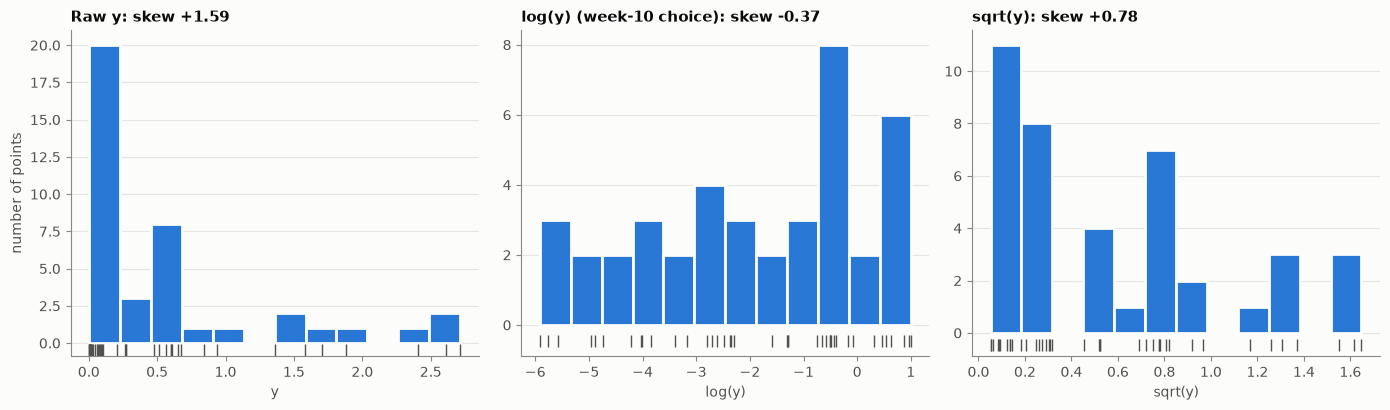

In [4]:
# -----------------------------------------------------------------------
# DATA TRANSFORMATION 
# -----------------------------------------------------------------------

TARGETS = {"log": (np.log(y), np.exp),
           "sqrt": (np.sqrt(y), lambda m: np.maximum(m, 0) ** 2),
           "raw": (y.copy(), lambda m: m)}
print('\n')
for k, (t, _) in TARGETS.items():
    print(f" Skew of {k:4s} target: {skew(t):+.2f}")

print('\n')

# Fig 2: target transforms
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (title, tname, xl) in zip(axes, [("Raw y", "raw", "y"), ("log(y) (week-10 choice)", "log", "log(y)"),
                                         ("sqrt(y)", "sqrt", "sqrt(y)")]):
    t = TARGETS[tname][0]
    ax.hist(t, bins=12, color=PAL[0], edgecolor=SURFACE, linewidth=2)
    ax.plot(t, np.full(n, -0.45), "|", color=INK2, markersize=9, clip_on=False)
    ax.set_title(f"{title}: skew {skew(t):+.2f}"); ax.set_xlabel(xl)
    ax.set_ylim(bottom=-0.9); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("number of points")
fig.tight_layout()


MODELS (LOO with hyperparameters fixed; raw-y errors for the best 6 points)
  log-ARD   ls=[1.76 1.24 0.88 0.61 0.54 0.82]  RMSE/std(own)=0.476  Spearman=0.887  95% cover=0.95  top-6 raw RMSE=0.014
  log-iso   ls=[0.71]  RMSE/std(own)=0.511  Spearman=0.884  95% cover=1.00  top-6 raw RMSE=0.113
  sqrt-ARD  ls=[1.27 0.84 1.67 0.51 0.36 0.46]  RMSE/std(own)=0.272  Spearman=0.924  95% cover=1.00  top-6 raw RMSE=0.029
  sqrt-iso  ls=[0.53]  RMSE/std(own)=0.399  Spearman=0.867  95% cover=1.00  top-6 raw RMSE=0.025
  raw-ARD   ls=[  0.11 100.   100.     0.49   0.5    0.22]  RMSE/std(own)=0.327  Spearman=0.713  95% cover=1.00  top-6 raw RMSE=0.033
  raw-iso   ls=[0.38]  RMSE/std(own)=0.341  Spearman=0.766  95% cover=1.00  top-6 raw RMSE=0.043




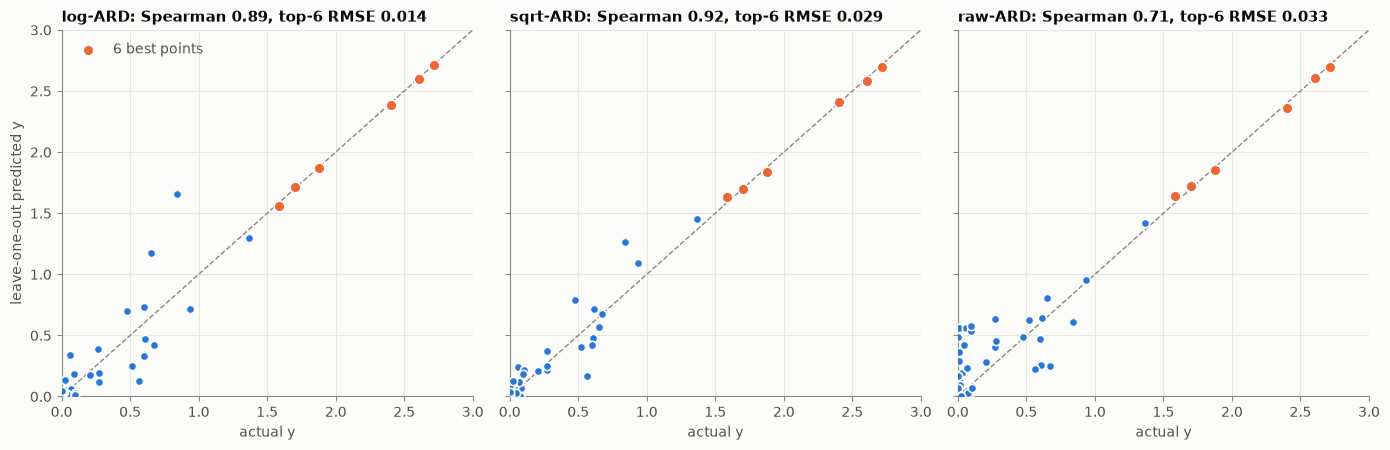

In [5]:
# -----------------------------------------------------------------------
# LOO cross-validation
# -----------------------------------------------------------------------

def fit(t, ard):
    k = (ConstantKernel(1.0, (1e-2, 1e3)) * Matern(length_scale=np.ones(d) if ard else 1.0,
                                      length_scale_bounds=(1e-2, 1e2), nu=2.5)
         + WhiteKernel(1e-2, (1e-6, 1.0)))
    return GaussianProcessRegressor(kernel=k, normalize_y=True, n_restarts_optimizer=25,
                                    random_state=SEED).fit(X, t)

top = np.argsort(-y)[:6]
models, loos = {}, {}
print("\nMODELS (LOO with hyperparameters fixed; raw-y errors for the best 6 points)")
for tname, (t, back) in TARGETS.items():
    for ard in (True, False):
        key = f"{tname}-{'ARD' if ard else 'iso'}"
        gp = fit(t, ard)
        mu, sd = np.empty(n), np.empty(n)
        for i in range(n):
            keep = np.arange(n) != i
            g = GaussianProcessRegressor(kernel=gp.kernel_, optimizer=None, normalize_y=True).fit(X[keep], t[keep])
            a, s = g.predict(X[i:i + 1], return_std=True)
            mu[i], sd[i] = a[0], s[0]
        models[key] = (gp, back)
        loos[key] = back(mu)
        ls = np.atleast_1d(gp.kernel_.k1.k2.length_scale)
        print(f"  {key:9s} ls={np.round(ls, 2)}  RMSE/std(own)={np.sqrt(np.mean((t - mu) ** 2)) / t.std():.3f}  "
              f"Spearman={spearmanr(y, loos[key])[0]:.3f}  95% cover={np.mean(np.abs((t - mu) / sd) < 1.96):.2f}  "
              f"top-6 raw RMSE={np.sqrt(np.mean((y[top] - loos[key][top]) ** 2)):.3f}")

def pred(key, Z):
    g, back = models[key]
    return back(g.predict(np.atleast_2d(Z)))
print('\n')
# Fig 3: LOO for the three ARD models, raw y
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
lim = [0, 3]
for ax, key in zip(axes, ["log-ARD", "sqrt-ARD", "raw-ARD"]):
    yb = loos[key]
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.scatter(y, yb, s=36, color=PAL[0], edgecolor=SURFACE, linewidth=1.2, zorder=3)
    ax.scatter(y[top], yb[top], s=60, color=PAL[1], edgecolor=SURFACE, linewidth=1.2, zorder=4, label="6 best points")
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel("actual y")
    ax.set_title(f"{key}: Spearman {spearmanr(y, yb)[0]:.2f}, top-6 RMSE {np.sqrt(np.mean((y[top] - yb[top]) ** 2)):.3f}")
axes[0].set_ylabel("leave-one-out predicted y")
axes[0].legend(frameon=False, loc="upper left", labelcolor=INK2)
fig.tight_layout()

In [6]:
# ---------------------------------------------------------------- 
# Candidates
# ---------------------------------------------------------------- 

S = qmc.Sobol(d, seed=1).random(2 ** 14)
def box_argmax(fn, r):
    lo, hi = np.clip(xb - r, 0, 1), np.clip(xb + r, 0, 1)
    Z = lo + S * (hi - lo); v = fn(Z); x0 = Z[v.argmax()]
    res = minimize(lambda q: -fn(q[None])[0], x0, bounds=list(zip(lo, hi)), method="L-BFGS-B")
    return res.x if -res.fun >= v.max() else x0

x_sqrt_box = box_argmax(lambda Z: models["sqrt-ARD"][0].predict(Z), 0.1)
cands = {
    "A: EI, log-ARD (week-10 script)": np.array([0.0, 0.0, 1.0, 1.0, 0.0, 1.0]),
    "B: EI, sqrt-ARD (week-10 script)": np.array([0.0, 0.162981, 0.728930, 0.276481, 0.333766, 0.632247]),
    "C: highest mean, sqrt-ARD (±0.1 box)": x_sqrt_box,
    "D: quarter-step towards C": xb + 0.25 * (x_sqrt_box - xb),
    "E: highest mean, log-ARD (±0.1 box)": box_argmax(lambda Z: models["log-ARD"][0].predict(Z), 0.1),
}
KEYS = list(models)
print("\nCANDIDATES: predicted y by each model (current best %.4f)" % y.max())
for name, xc in cands.items():
    print(f"  {name:38s} x = ({', '.join(f'{v:.6f}' for v in xc)})  dist {np.linalg.norm(xc - xb):.3f}  "
          + "  ".join(f"{k}={pred(k, xc)[0]:.3f}" for k in KEYS))


CANDIDATES: predicted y by each model (current best 2.7144)
  A: EI, log-ARD (week-10 script)        x = (0.000000, 0.000000, 1.000000, 1.000000, 0.000000, 1.000000)  dist 1.054  log-ARD=0.828  log-iso=0.472  sqrt-ARD=0.653  sqrt-iso=0.528  raw-ARD=0.515  raw-iso=0.585
  B: EI, sqrt-ARD (week-10 script)       x = (0.000000, 0.162981, 0.728930, 0.276481, 0.333766, 0.632247)  dist 0.334  log-ARD=1.408  log-iso=1.227  sqrt-ARD=2.847  sqrt-iso=1.458  raw-ARD=2.702  raw-iso=1.531
  C: highest mean, sqrt-ARD (±0.1 box)   x = (0.000000, 0.172662, 0.499928, 0.283189, 0.330421, 0.632319)  dist 0.111  log-ARD=2.477  log-iso=2.454  sqrt-ARD=2.825  sqrt-iso=2.499  raw-ARD=2.706  raw-iso=2.506
  D: quarter-step towards C              x = (0.000000, 0.199828, 0.424928, 0.304918, 0.327286, 0.641121)  dist 0.028  log-ARD=2.699  log-iso=2.701  sqrt-ARD=2.752  sqrt-iso=2.700  raw-ARD=2.715  raw-iso=2.699
  E: highest mean, log-ARD (±0.1 box)    x = (0.000000, 0.202864, 0.397498, 0.312174, 0.329175, 0.6

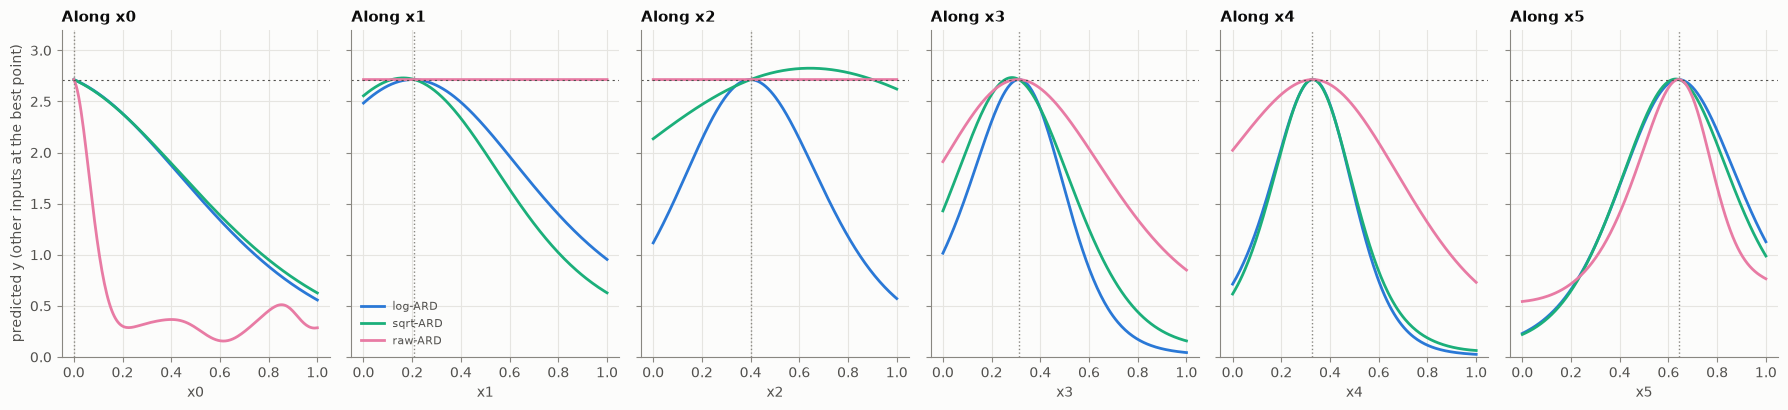

In [7]:
# Fig 4: slices of log-ARD and sqrt-ARD through the best point
fig, axes = plt.subplots(1, d, figsize=(18, 4.2), sharey=True)
xs = np.linspace(0, 1, 200)
for j, ax in enumerate(axes):
    Z = np.tile(xb, (len(xs), 1)); Z[:, j] = xs
    for key, col in [("log-ARD", PAL[0]), ("sqrt-ARD", PAL[2]), ("raw-ARD", PAL[4])]:
        ax.plot(xs, pred(key, Z), color=col, lw=2, label=key)
    ax.axvline(xb[j], color=MUTED, lw=1, ls=":")
    ax.axhline(y.max(), color=INK2, lw=0.8, ls=(0, (2, 3)))
    ax.set_xlabel(f"x{j}"); ax.set_title(f"Along x{j}"); ax.set_ylim(0, 3.2)
axes[0].set_ylabel("predicted y (other inputs at the best point)")
axes[1].legend(frameon=False, fontsize=8, loc="lower left", labelcolor=INK2)
fig.tight_layout()